# 04 交叉分析、项目评分卡与运营建议

**组织**：迪庆清风青年公益联合会（云南省迪庆藏族自治州）
**数据**：`data/processed/` 星型模型 + 项目评分卡 + 队列 / 集中度产物
**定位**：本 notebook 是整条分析链的**落地环节**——把前三个 notebook 的结论收敛成可执行的运营动作。

---

## 本 notebook 要回答的业务问题

1. 志愿者结构、捐赠渠道、服务对象家庭类型之间，是否存在**统计显著**的结构性差异？（而不是看起来有差异）
2. 52 个项目放在同一张评分卡上，谁优秀、谁需要复盘？评价用的是投入、执行、产出、质量四组指标，而不是单一满意度。
3. 捐赠收入集中度有多高？如果头部捐赠人流失，资金缺口有多大？剔除一次性大额捐赠后的"可比口径"是什么样？
4. 志愿者队列的留存状况如何？哪些年份的队列需要激活？
5. **综合以上，下一季度具体该做哪几件事？**

## 数据来源说明

| 数据 | 路径 | 用途 |
| --- | --- | --- |
| 交叉分析列联表 | `data/processed/crosstab_*.csv` | 卡方检验与行内占比 |
| 项目评分卡 | `data/processed/project_scorecard.csv` | 项目级投入产出评价 |
| 集中度与帕累托 | `data/processed/concentration_pareto.csv`、`top_donors.csv` | 资金集中度风险 |
| 队列留存 | `data/processed/cohort_retention.csv` | 志愿者留存画像 |
| 相关矩阵 | `data/processed/correlation_matrix.csv` | 指标间关系 |
| 县域维度汇总 | `qingfeng.metrics.dimension_breakdown` | 县域资源配置均衡度 |

> 方法论说明：交叉分析一律同时给出**卡方检验 p 值与 Cramér's V 效应量**。
> 只看 p 值会被大样本"骗"——样本量足够大时，任何微小差异都会显著；效应量才回答"差异有多大、值不值得行动"。
> 项目评分卡采用**分位数标准化加权**，避免不同量纲的指标直接相加；权重与口径在代码中显式写出。

## 结论摘要

- **交叉维度普遍存在显著关联，但效应量差异很大**：渠道 × 捐赠人类型、服务对象年龄段 × 服务类型的关联达到中等强度（属于"制度性分工"，可以直接拿来配置资源）；家庭类型 × 满意度档的关联在统计上极显著但效应量偏弱——这是一条"幅度小、方向明确、且涉及服务公平性"的差距，值得行动，但不应夸大。
- **项目评分卡呈现"中间大、两头小"**：多数项目落在合格与良好区间，真正优秀的项目很少，也有一批需要重点复盘的待改进项目。评分卡的价值不在于排名，而在于让"复盘名单"有据可依。
- **投入规模不等于服务质量**：执行率偏高或偏低、单位成本高或低，与满意度都不构成单调关系；高分项目是在"执行稳、覆盖足、成本合理、满意度高"四项上同时不掉队。
- **捐赠收入高度集中**：少数捐赠人贡献了绝大部分金额，集中度指标处于需要主动管理风险的区间。一次性大额捐赠会显著抬高当期支出与预算基线，必须用"剔除后可比口径"评估可持续筹资能力。
- **志愿者留存是最大的隐性产能缺口**：各年队列的留存率随时间衰减，注册满一年后仍有服务记录的比例偏低，说明招募强于留存。
- **行动建议**：本 notebook 最后给出 8 条带量化依据的具体动作，覆盖项目复盘、服务公平性、资金风险、志愿者激活、季节排班与数据治理。

In [1]:
%matplotlib inline
import logging
import re
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from qingfeng.config import load_config
from qingfeng.pipeline import load_artifacts, load_cleaning_log
from qingfeng.viz import setup_style

warnings.filterwarnings("ignore")
logging.getLogger("qingfeng").setLevel(logging.WARNING)   # 管道内部 INFO 日志不进入 notebook 输出
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)

cfg = load_config()                      # 所有路径均已解析为绝对路径
arts = load_artifacts(cfg)               # 复用管道产物，避免重复计算
star = arts["star"]
cleaned = arts["cleaned"]
log = load_cleaning_log(cfg)
FIG = cfg.paths.figures
setup_style(cfg)                         # 复用管道的中文字体与配色，保证图文风格一致

print(f"分析对象：{cfg.org_name}（{cfg.region}）")
print(f"数据窗口：{cfg.simulation.start_date} ~ {cfg.simulation.as_of_date}")
print(f"随机种子：{cfg.simulation.seed}（数据完全可复现）")


def show(fig, name: str, caption: str = ""):
    # 落盘并内嵌显示自绘图表，保证图表数据被写进 .ipynb 输出
    path = FIG / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))
    if caption:
        print(caption)
    print(f"（本 notebook 自绘图表已保存：{path.relative_to(cfg.paths.root)}）")


def pipeline_figure(name: str, caption: str = ""):
    # 直接引用管道已产出的图表
    path = FIG / name
    display(Image(filename=str(path)))
    if caption:
        print(caption)
    
from qingfeng.analyze import (cross_analysis, build_cross_datasets, chi_square_test,
                              cohort_retention, concentration_analysis, gini_coefficient,
                              correlation_analysis, donation_service_elasticity, project_scorecard,
                              monthly_seasonality)
from qingfeng.metrics import dimension_breakdown

scorecard = arts["project_scorecard"].copy()
cross_tests = cross_analysis(cfg, star)
cross_tables = build_cross_datasets(cfg, star)
panel = arts["monthly_panel"].copy()
print(f"项目评分卡：{len(scorecard)} 个项目、{scorecard.shape[1]} 个字段")
print(f"交叉分析：{len(cross_tests)} 组列联表；评分卡评级分布 "
      f"{scorecard['评级'].value_counts().to_dict()}")

分析对象：迪庆清风青年公益联合会（云南省迪庆藏族自治州）
数据窗口：2024-01-01 ~ 2026-06-30
随机种子：20260601（数据完全可复现）
项目评分卡：52 个项目、34 个字段
交叉分析：6 组列联表；评分卡评级分布 {'B 良好': 20, 'C 合格': 20, 'D 待改进': 9, 'A 优秀': 3}


## 1. 交叉分析：差异是否"统计显著"且"值得行动"

交叉分析回答的是分组结构问题。项目里固化了六组与业务直接相关的列联表，每一组对应一个真实问题：

| 交叉分析 | 对应的业务问题 |
| --- | --- |
| 志愿者民族 × 项目类别 | 服务供给是否覆盖各民族聚居区的需求？ |
| 县域 × 服务角色 | 各县志愿者的角色结构是否有系统差异？ |
| 捐赠渠道 × 捐赠人类型 | 机构与个人走的渠道是否不同（决定募款投入方向）？ |
| 家庭类型 × 满意度档 | 越脆弱的家庭是否满意度越低（服务质量公平性）？ |
| 志愿者年龄段 × 服务类型 | 青年与中老年志愿者是否存在分工差异？ |
| 服务对象年龄段 × 服务类型 | 服务类型是否匹配不同年龄段的真实需求？ |

判读规则：**p < 0.05 说明维度间不独立；Cramér's V 说明关联强度**（<0.1 弱、0.1–0.3 中等、≥0.5 强）。

,交叉分析,样本量,卡方值,自由度,p值,Cramér's V,是否显著,结论
0,志愿者民族×项目类别,12490,82.9234,63,4.704488e-02,0.0308,是,两维度显著相关（p=0.04704 < 0.05），关联强度弱（V=0.031）
1,县域×服务角色,12785,41.4375,24,1.490641e-02,0.0329,是,两维度显著相关（p=0.01491 < 0.05），关联强度弱（V=0.033）
2,志愿者年龄段×服务类型,12490,62.8620,35,2.638854e-03,0.0317,是,两维度显著相关（p=0.002639 < 0.05），关联强度弱（V=0.032）
3,捐赠渠道×捐赠人类型,19829,18638.9223,30,0.000000e+00,0.4336,是,两维度显著相关（p=0 < 0.05），关联强度中等（V=0.434）
4,家庭类型×满意度档,15828,427.3217,21,2.022876e-77,0.0949,是,两维度显著相关（p=2.023e-77 < 0.05），关联强度弱（V=0.095）
5,服务对象年龄段×服务类型,15828,14734.0681,48,0.000000e+00,0.3939,是,两维度显著相关（p=0 < 0.05），关联强度中等（V=0.394）


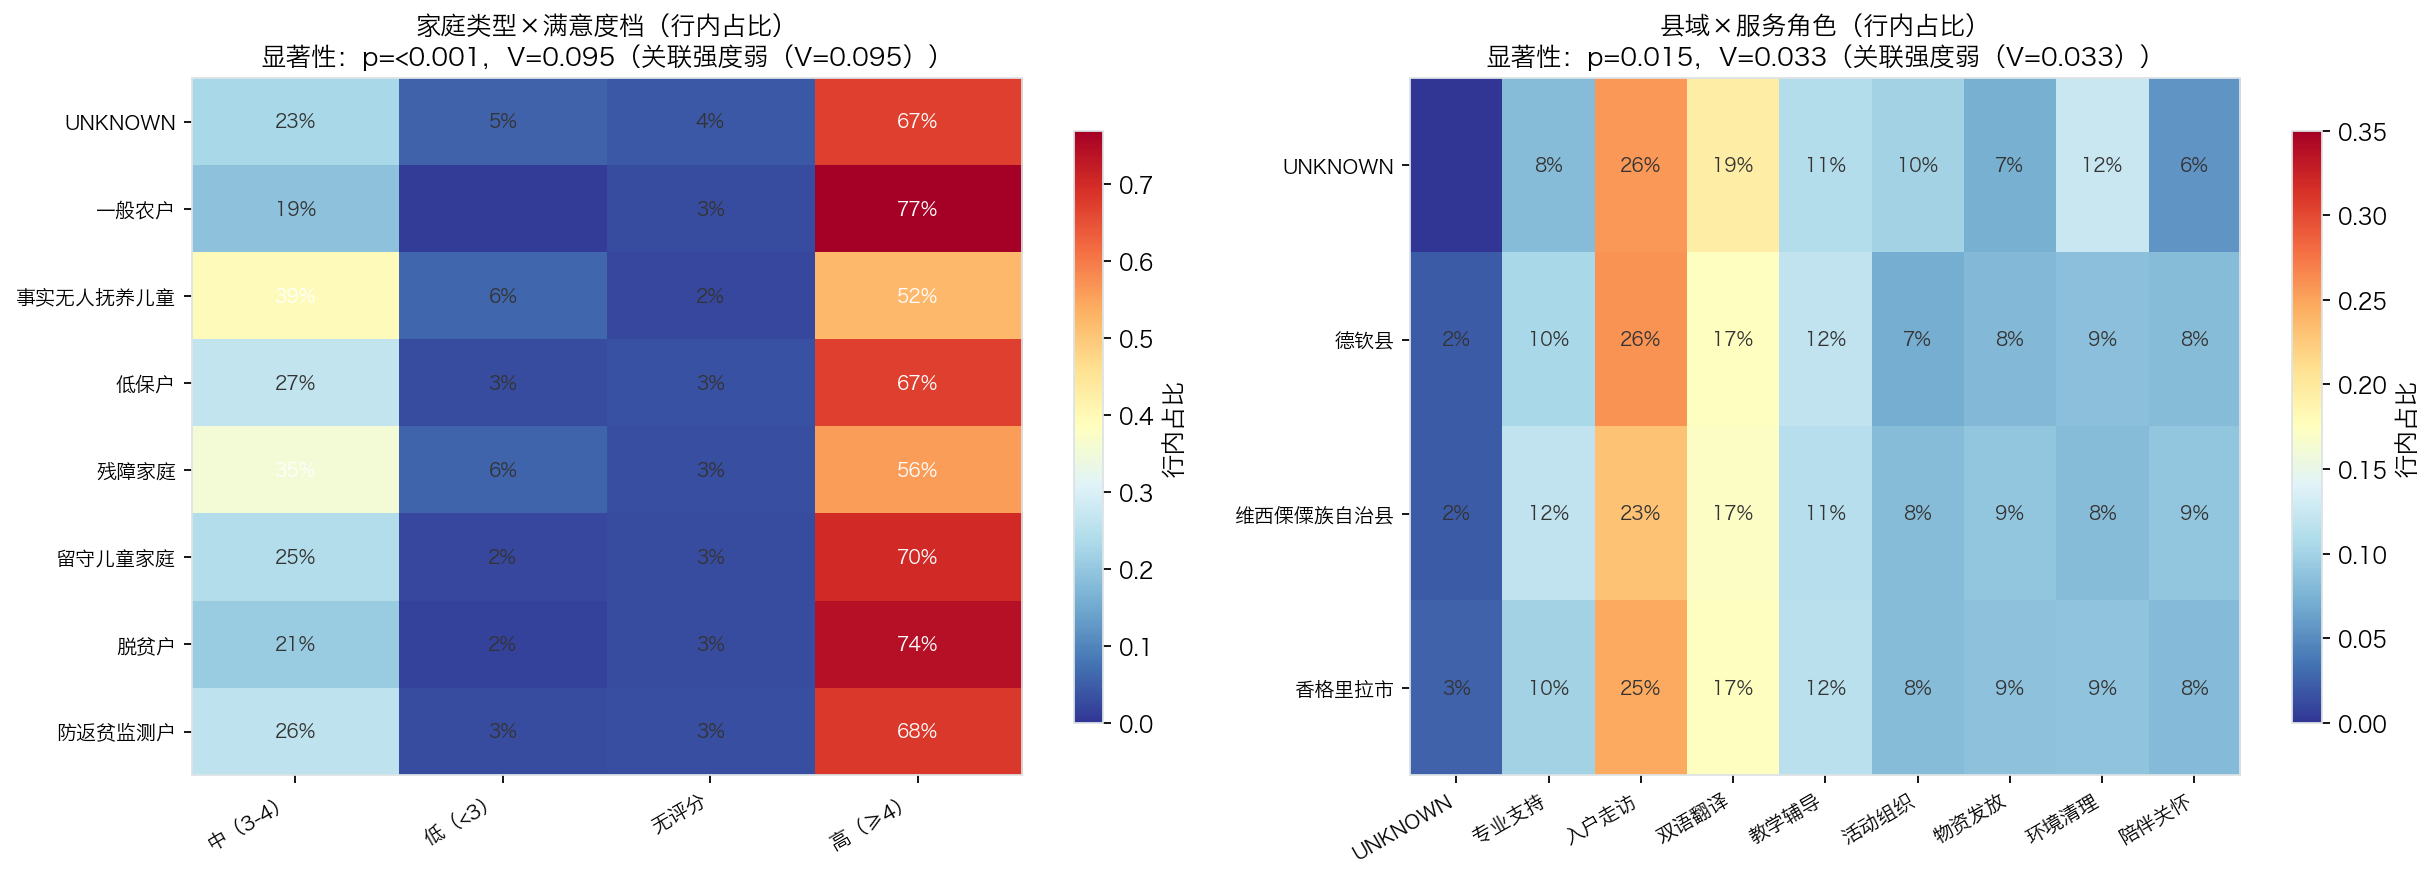

左图回答“服务质量是否公平”，右图回答“县域角色结构是否有差异”——两张图都不在管道默认产出中，因此在此单独绘制。
（本 notebook 自绘图表已保存：reports/figures/nb04_cross_tables.png）


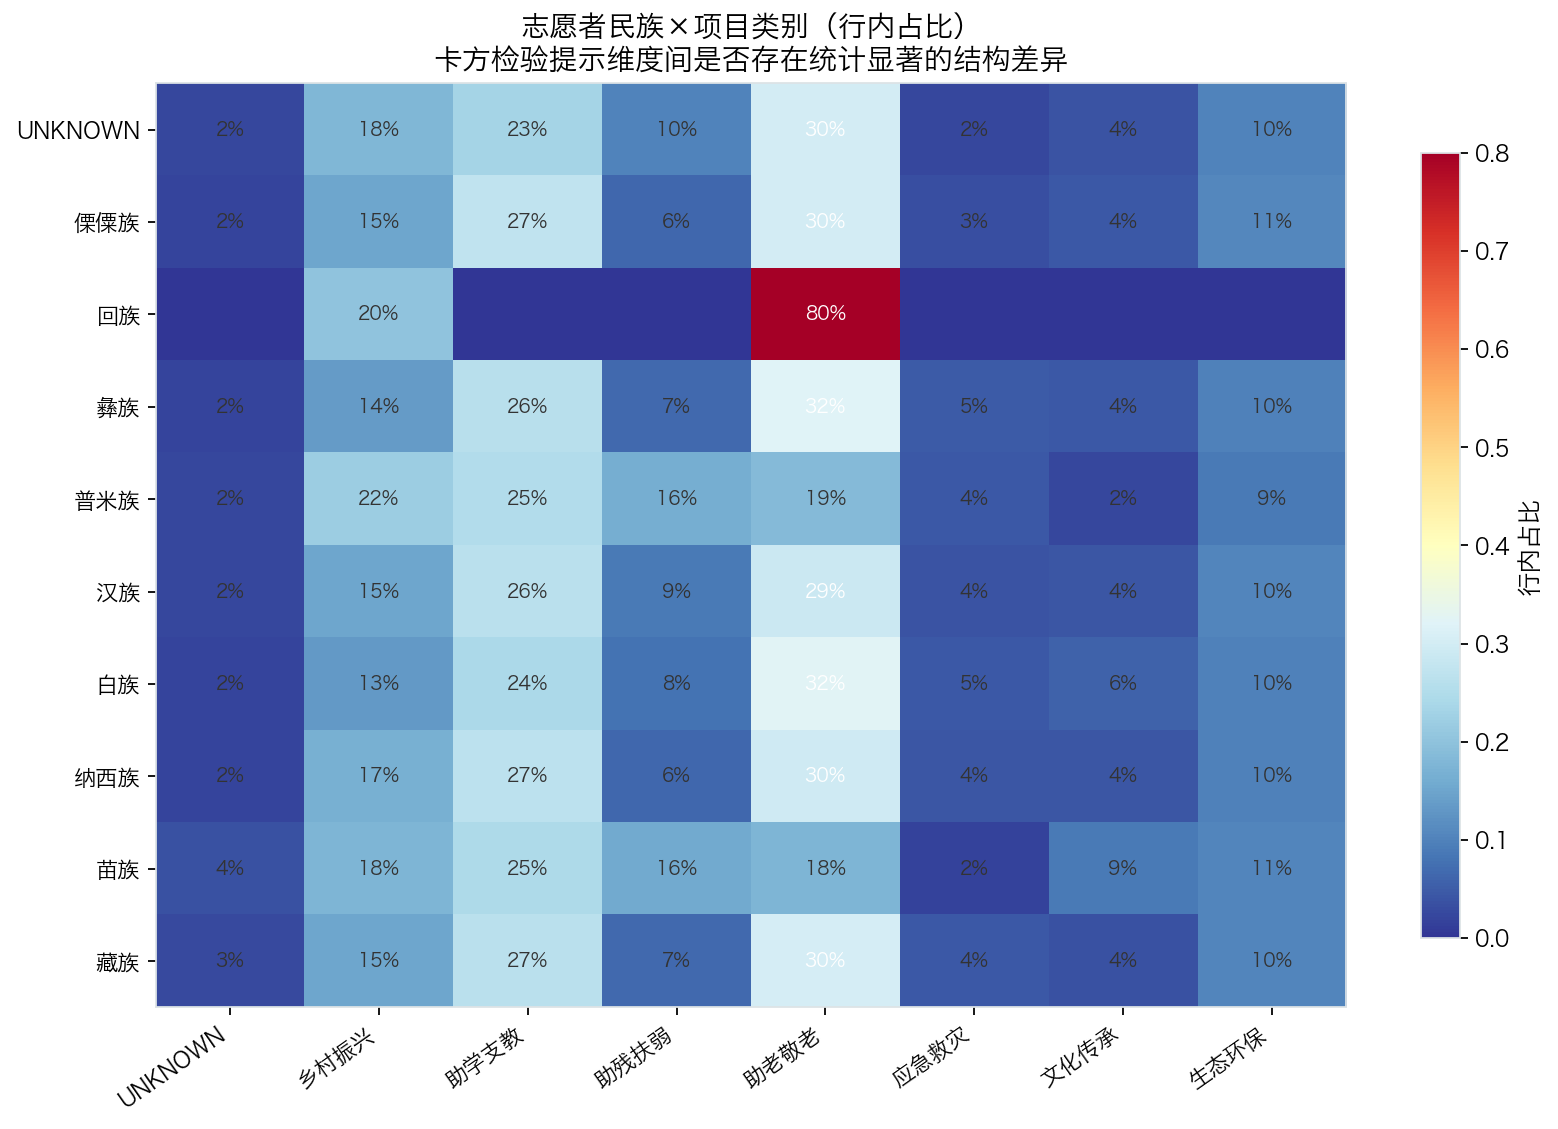

管道产出的民族 × 项目类别交叉热力图（行内占比）。


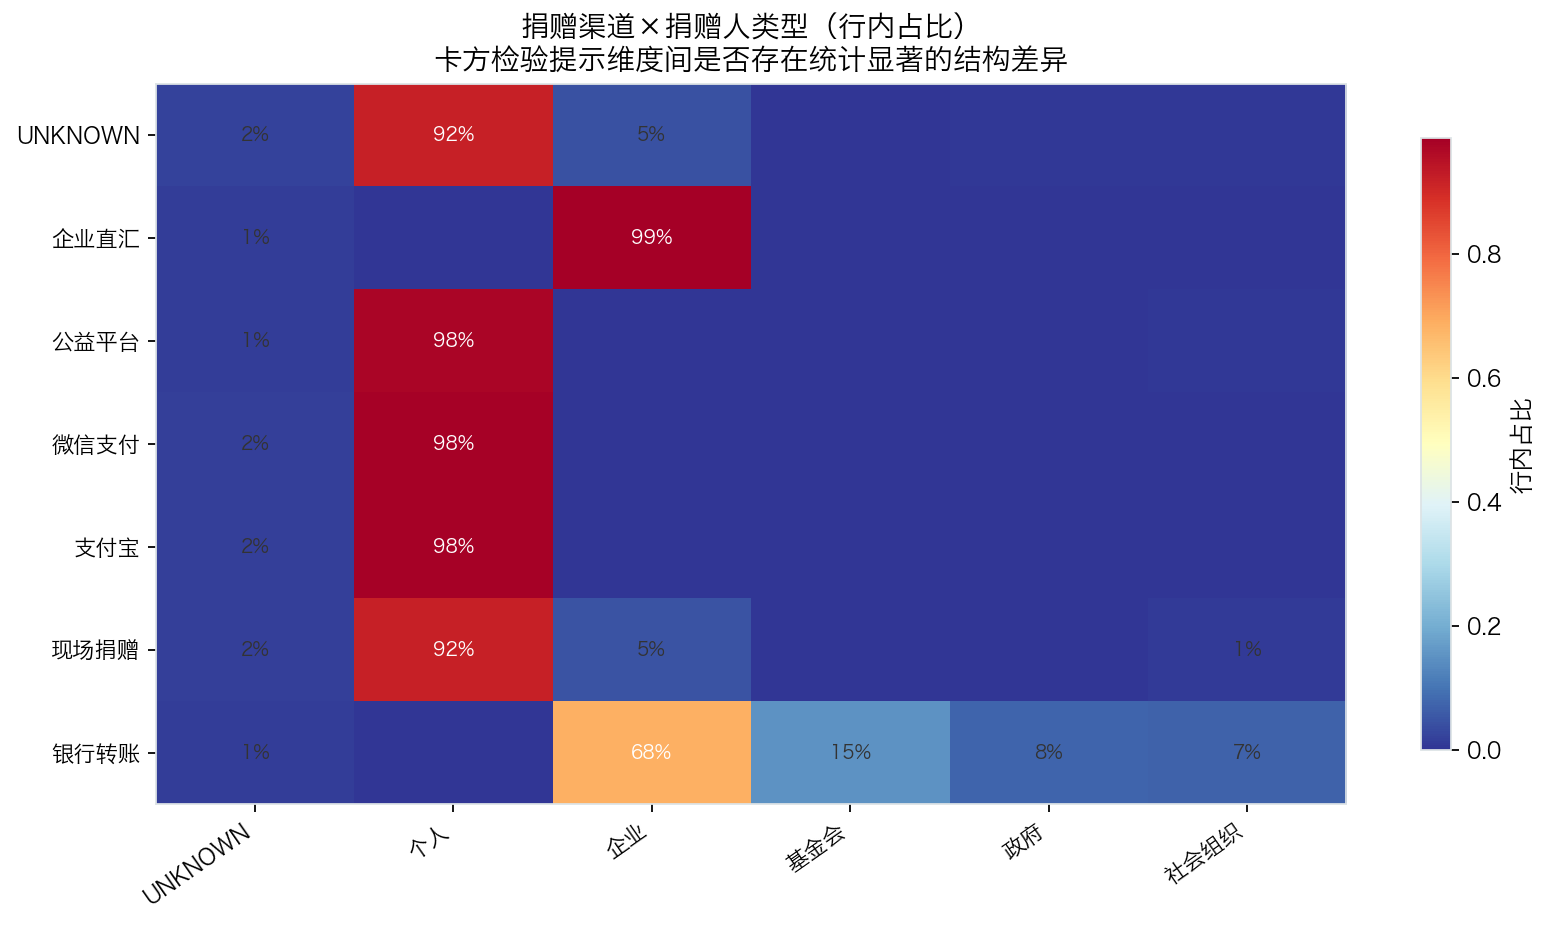

管道产出的捐赠渠道 × 捐赠人类型交叉热力图。


In [2]:
display(cross_tests[["交叉分析", "样本量", "卡方值", "自由度", "p值", "Cramér's V", "是否显著", "结论"]])

KEY_TABLES = ["家庭类型×满意度档", "县域×服务角色"]
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.6))
for ax, key in zip(axes, KEY_TABLES):
    ct = cross_tables[key]
    share = ct.div(ct.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)
    im = ax.imshow(share.to_numpy(), aspect="auto", cmap="RdYlBu_r", vmin=0,
                   vmax=max(0.35, share.to_numpy().max()))
    ax.set_xticks(range(len(share.columns)), [str(c) for c in share.columns], rotation=30, ha="right", fontsize=9)
    ax.set_yticks(range(len(share.index)), [str(i) for i in share.index], fontsize=9)
    for i in range(share.shape[0]):
        for j in range(share.shape[1]):
            v = share.iloc[i, j]
            if v >= 0.01:
                ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8.5,
                        color="white" if v > 0.28 else "#333333")
    res = chi_square_test(ct)
    subtitle = ("显著性：p=" + ("<0.001" if res["p_value"] < 0.001 else f"{res['p_value']:.3f}")
                + f"，V={res['cramers_v']:.3f}（{res['conclusion'].split('），')[-1]}）")
    ax.set_title(f"{key}（行内占比）\n{subtitle}", fontsize=11.5)
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="行内占比", shrink=0.85)
fig.tight_layout()
show(fig, "nb04_cross_tables",
     "左图回答“服务质量是否公平”，右图回答“县域角色结构是否有差异”——两张图都不在管道默认产出中，"
     "因此在此单独绘制。")

pipeline_figure("05_crosstab_heatmap.png", "管道产出的民族 × 项目类别交叉热力图（行内占比）。")
pipeline_figure("05b_crosstab_channel.png", "管道产出的捐赠渠道 × 捐赠人类型交叉热力图。")

**交叉分析的判读要点**：

1. **先看显著性，再看效应量**。本数据集样本量是万级，"显著"几乎是必然的；
   真正决定投入优先级的是 Cramér's V：V 达到中等以上（≥0.3）说明维度间存在**结构性分工**，可以据此配置资源；
   V 很小（<0.1）说明差异幅度有限，通常不值得单独投入。
2. **两类关联必须区别对待**：
   - **运营类关联**（渠道 × 捐赠人类型、服务对象年龄段 × 服务类型）效应量达到中等强度，说明分工是制度性的、可设计的，
     应直接用于募款与项目资源配置；
   - **公平类关联**（家庭类型 × 满意度档）即使效应量偏弱也必须行动——服务质量差距涉及伦理与公信力，
     判断标准不是效应量大小，而是**方向是否系统性地不利于脆弱群体**。它与 notebook 02 的置信区间结论互为印证。
3. **县域 × 服务角色**反映的是资源禀赋差异：交通不便的县更多依赖巡护与入户走访，
   中心城区更多承担活动组织与培训。这种差异**不是问题**，但意味着**考核指标不能一刀切**——
   用同一套"服务人次"目标考核所有县，会系统性惩罚边远县。
4. **捐赠渠道 × 捐赠人类型**直接指导募款投入：机构捐赠与个人捐赠的渠道偏好不同，
   应该为两类捐赠人配置不同的触达方式（一个是关系型、一个是产品型）。

> 决策原则：交叉分析只用来**发现结构**，具体行动必须回到项目层面。下一节的评分卡就是把结构问题落到项目上。

## 2. 项目评分卡：把 52 个项目放进同一把尺子

评分卡用四组指标构成综合评价：

| 维度 | 指标 | 权重 | 方向 |
| --- | --- | --- | --- |
| 执行 | 预算执行率 | 25% | 越接近 1 越好（本卡用分位数排序近似） |
| 覆盖 | 目标覆盖率（实际建档 / 目标受益人数） | 25% | 越高越好 |
| 质量 | 服务满意度均值 | 25% | 越高越好 |
| 效率 | 单位服务成本 | 25% | 越低越好（反向排序） |

四个维度各自做**分位数标准化**后加权，避免量纲差异；评级按综合评分分档。
下面同时给出类别与县域两个视角的汇总，用于判断"问题是个别项目还是普遍现象"。

评级分布： {'A 优秀': 3, 'B 良好': 20, 'C 合格': 20, 'D 待改进': 9}

综合评分 Top 5：


,project_name,category,county,execution_rate,target_coverage,satisfaction_mean,cost_per_visit,综合评分,评级
0,维西-康复辅具适配(1期),助残扶弱,维西傈僳族自治县,1.086,0.832,4.329,560.25,0.851,A 优秀
1,维西-特殊儿童融合课堂,助残扶弱,维西傈僳族自治县,1.118,0.846,4.300,695.02,0.812,A 优秀
2,香格里拉-敬老院暖心厨房(2期),助老敬老,香格里拉市,1.071,0.843,4.287,649.05,0.757,A 优秀
3,香格里拉-高原藜麦助销计划,乡村振兴,香格里拉市,1.097,0.806,4.274,625.33,0.716,B 良好
4,德钦县-独居老人关爱探访,助老敬老,德钦县,0.985,0.823,4.329,848.06,0.712,B 良好


综合评分 Bottom 5（复盘名单）：


,project_name,category,county,execution_rate,target_coverage,satisfaction_mean,cost_per_visit,综合评分,评级
51,德钦县-青苗暑期支教营,助学支教,德钦县,0.784,0.707,4.192,2079.81,0.091,D 待改进
50,香格里拉-草原垃圾清零,生态环保,香格里拉市,0.891,0.692,4.223,17515.52,0.135,D 待改进
49,维西-村寨微景观改造,乡村振兴,维西傈僳族自治县,0.855,0.617,4.280,3380.49,0.183,D 待改进
48,维西-雪灾应急物资投送,应急救灾,维西傈僳族自治县,0.767,0.797,4.232,1738.74,0.240,D 待改进
47,香格里拉-夕阳红健康巡诊(1期),助老敬老,香格里拉市,0.789,0.750,4.243,1127.31,0.250,D 待改进


,项目数,实际支出,执行率均值,满意度均值,单位成本中位数,综合评分均值
category,,,,,,
文化传承,3,585433.98,0.924,4.348,676.780,0.609
助残扶弱,5,914176.31,1.008,4.295,949.840,0.598
助老敬老,14,3072086.27,0.988,4.286,821.985,0.566
助学支教,13,6195352.61,0.908,4.276,912.320,0.462
乡村振兴,9,3372492.15,0.929,4.266,1038.270,0.449
生态环保,5,1398313.88,0.926,4.332,8987.350,0.412
应急救灾,2,818292.11,0.882,4.243,1799.725,0.369


,county,registered_volunteers,bilingual_volunteers,service_hours,service_count,volunteer_value_cny,hours_per_10k_donation,donation_amount,donation_count,service_visits,satisfaction_mean
0,香格里拉市,1810,363.0,25604.95,6302,768148.6,52.42,4884896.07,7001,8386.0,4.29
1,维西傈僳族自治县,987,196.0,14383.19,3531,431495.7,59.42,2420528.35,4644,5014.0,4.29
2,德钦县,773,161.0,11322.43,2664,339673.0,108.07,1047734.69,2041,2737.0,4.24
3,UNKNOWN,30,5.0,1225.67,288,36770.1,3.25,3768542.87,5885,0.0,0.00


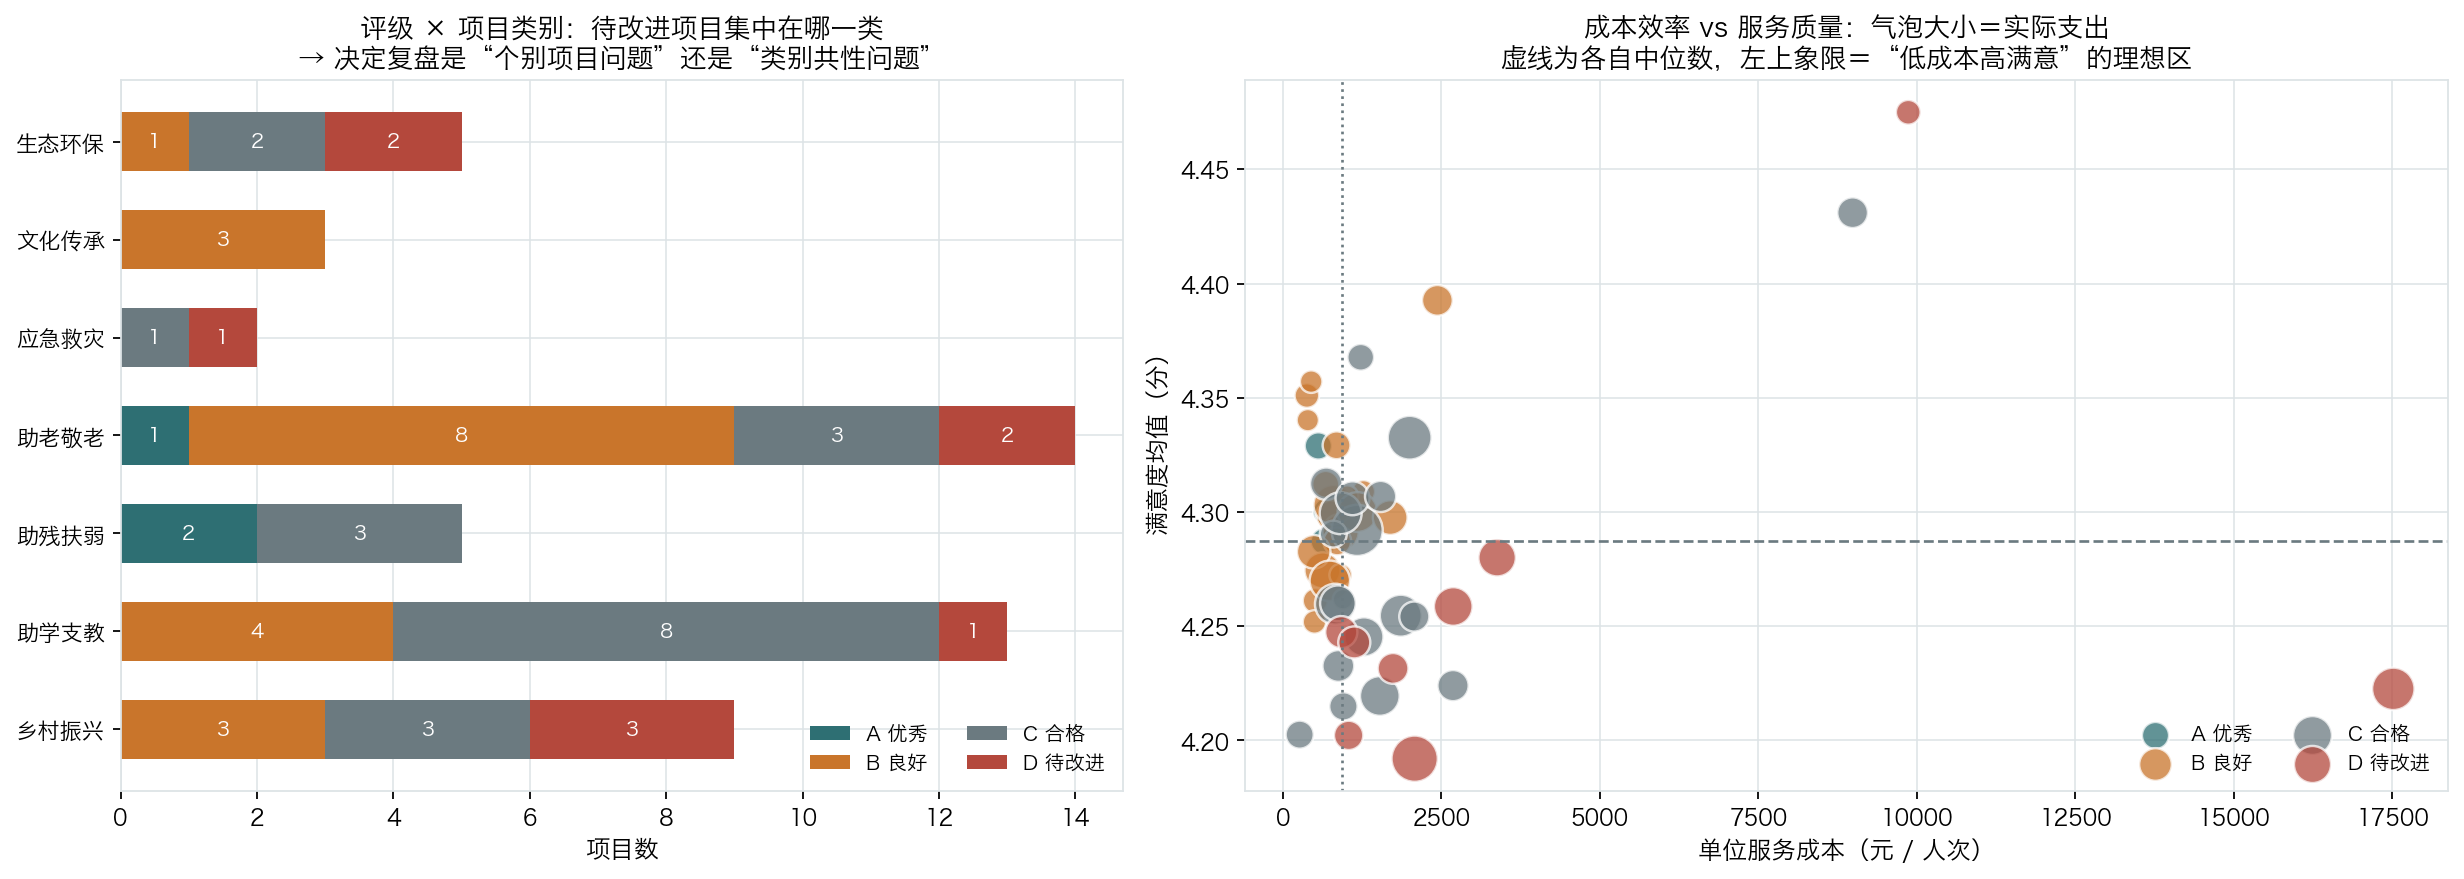

综合评分最高的是「维西-康复辅具适配(1期)」（0.851 分），最低的是「德钦县-青苗暑期支教营」（0.091 分）；待改进项目 9 个。
（本 notebook 自绘图表已保存：reports/figures/nb04_scorecard.png）


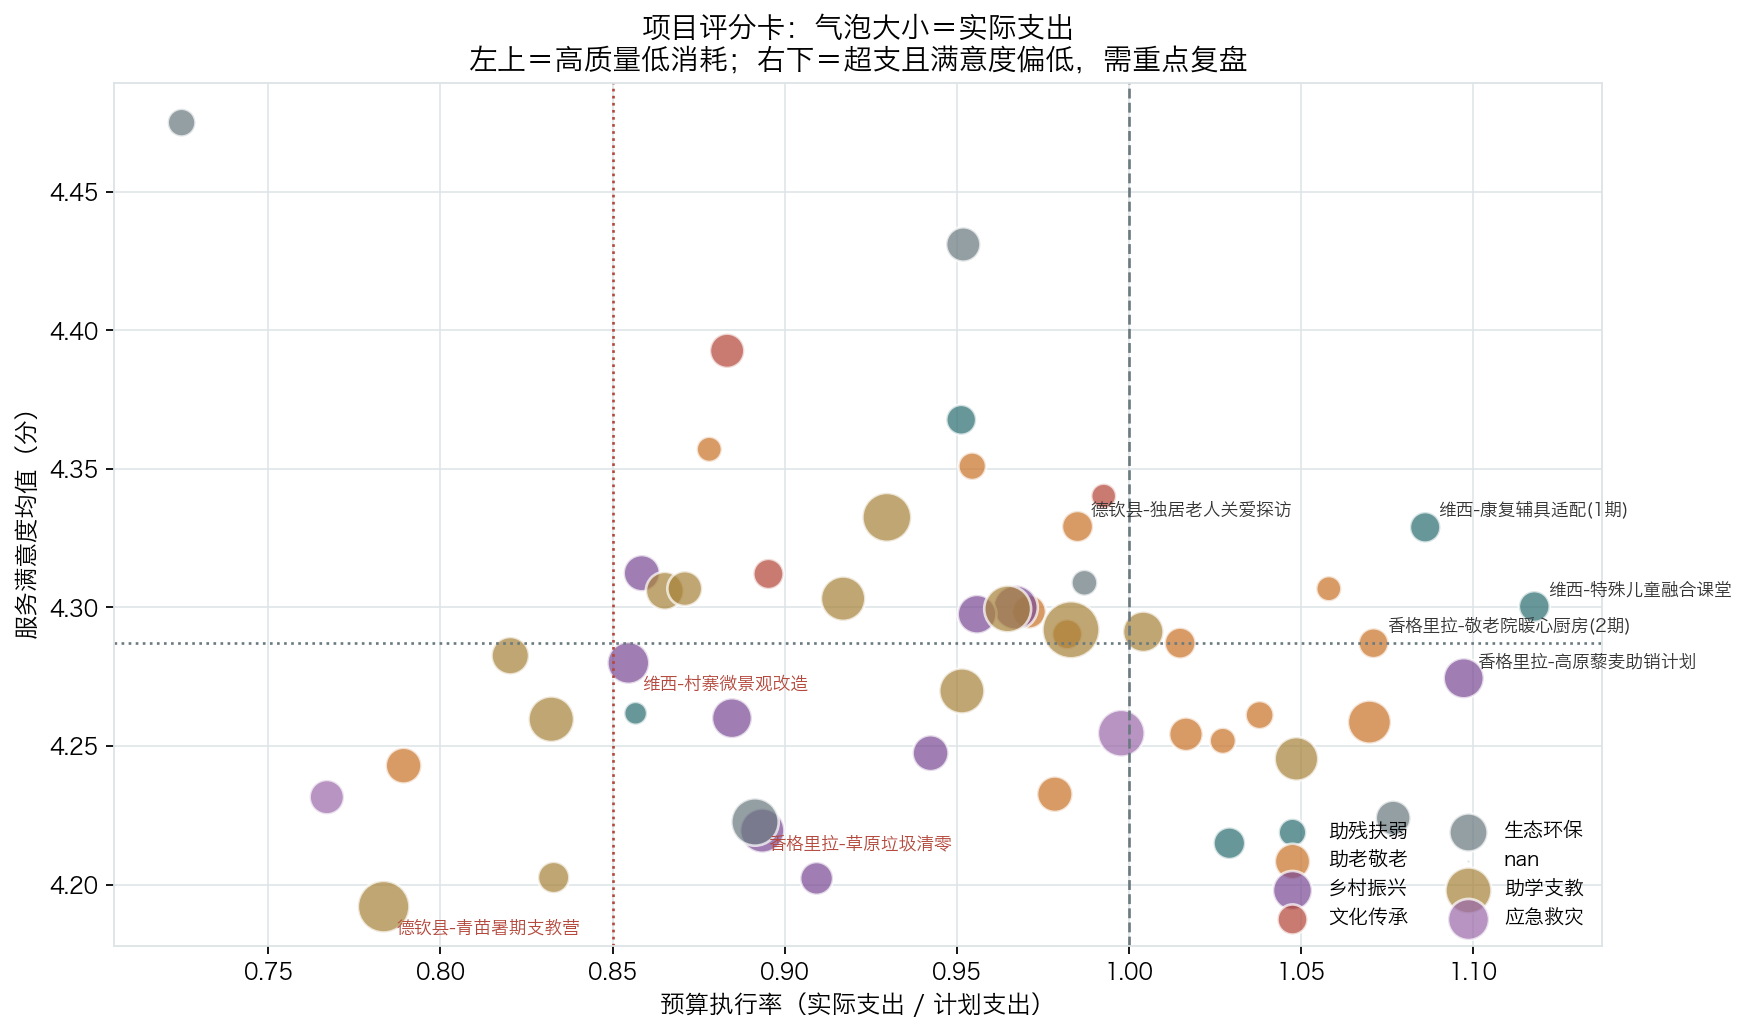

管道产出的项目评分卡：横轴预算执行率、纵轴满意度，气泡大小＝实际支出。


In [3]:
by_grade = scorecard["评级"].value_counts().reindex(["A 优秀", "B 良好", "C 合格", "D 待改进"]).fillna(0).astype(int)
print("评级分布：", by_grade.to_dict())

top5 = scorecard.nlargest(5, "综合评分")[["project_name", "category", "county", "execution_rate",
                                          "target_coverage", "satisfaction_mean", "cost_per_visit", "综合评分", "评级"]]
bottom5 = scorecard.nsmallest(5, "综合评分")[["project_name", "category", "county", "execution_rate",
                                              "target_coverage", "satisfaction_mean", "cost_per_visit", "综合评分", "评级"]]
print("\n综合评分 Top 5：")
display(top5.round(3))
print("综合评分 Bottom 5（复盘名单）：")
display(bottom5.round(3))

by_cat = (scorecard.groupby("category", dropna=True)
          .agg(项目数=("project_key", "size"), 实际支出=("actual_cny", "sum"),
               执行率均值=("execution_rate", "mean"), 满意度均值=("satisfaction_mean", "mean"),
               单位成本中位数=("cost_per_visit", "median"), 综合评分均值=("综合评分", "mean"))
          .sort_values("综合评分均值", ascending=False))
display(by_cat.round(3))

county_view = dimension_breakdown(cfg, star, "county")
display(county_view.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.6), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
grade_cat = (scorecard.dropna(subset=["category"])
             .pivot_table(index="category", columns="评级", values="project_key", aggfunc="count", fill_value=0))
grade_cat = grade_cat.reindex(columns=[c for c in ["A 优秀", "B 良好", "C 合格", "D 待改进"]
                                      if c in grade_cat.columns], fill_value=0)
left = np.zeros(len(grade_cat))
grade_colors = {"A 优秀": cfg.color("primary"), "B 良好": cfg.color("secondary"),
                "C 合格": cfg.color("neutral"), "D 待改进": cfg.color("danger")}
for col in grade_cat.columns:
    ax.barh(grade_cat.index, grade_cat[col], left=left, color=grade_colors[col], label=col, height=0.6)
    for y, (v, l) in enumerate(zip(grade_cat[col], left)):
        if v:
            ax.text(l + v / 2, y, str(int(v)), ha="center", va="center", color="white", fontsize=9,
                    fontweight="bold")
    left = left + grade_cat[col].to_numpy()
ax.set_xlabel("项目数")
ax.set_title("评级 × 项目类别：待改进项目集中在哪一类\n→ 决定复盘是“个别项目问题”还是“类别共性问题”", fontsize=12)
ax.legend(loc="lower right", ncols=2, fontsize=9)

ax = axes[1]
df = scorecard.dropna(subset=["cost_per_visit", "satisfaction_mean"])
size = 30 + 500 * (df["actual_cny"] / df["actual_cny"].max()).fillna(0)
for grade, sub in df.groupby("评级"):
    ax.scatter(sub["cost_per_visit"], sub["satisfaction_mean"], s=size[sub.index], alpha=0.75,
               color=grade_colors.get(grade, cfg.color("neutral")), edgecolor="white", lw=1.1, label=grade)
ax.axvline(df["cost_per_visit"].median(), ls=":", color=cfg.color("neutral"), lw=1.2)
ax.axhline(df["satisfaction_mean"].median(), ls="--", color=cfg.color("neutral"), lw=1.2)
ax.set_xlabel("单位服务成本（元 / 人次）")
ax.set_ylabel("满意度均值（分）")
ax.set_title("成本效率 vs 服务质量：气泡大小＝实际支出\n虚线为各自中位数，左上象限＝“低成本高满意”的理想区", fontsize=12)
ax.legend(loc="lower right", fontsize=9, ncols=2)
fig.tight_layout()
show(fig, "nb04_scorecard",
     f"综合评分最高的是「{scorecard.iloc[0]['project_name']}」（{scorecard.iloc[0]['综合评分']:.3f} 分），"
     f"最低的是「{scorecard.iloc[-1]['project_name']}」（{scorecard.iloc[-1]['综合评分']:.3f} 分）；"
     f"待改进项目 {int(by_grade['D 待改进'])} 个。")

pipeline_figure("10_project_scorecard.png",
                "管道产出的项目评分卡：横轴预算执行率、纵轴满意度，气泡大小＝实际支出。")

**评分卡怎么用于管理**：

- **不要用它做排名奖惩，要用它做复盘分类**。评分是分位数标准化的相对值，随项目集合变化；
  把它当绝对绩效会有误导。它的正确用法是回答"先复盘谁"。
- **两个象限最值得关注**：
  - **高成本 + 低满意度**（右下）：投入大却没有换来体验，优先排查执行方式（人员稳定性、双语匹配、服务设计）。
  - **低成本 + 低满意度**（左下）：投入不足导致服务缩水，属于资源分配问题，需要追加预算或缩减目标。
- **类别视角决定复盘方式**：如果待改进项目集中在某一类别，说明是**类别共性问题**（方法论、人员配置、物资供应），
  应做类别级专题复盘；如果分散在多个类别，则是**个别项目问题**，走项目负责人复盘。
- **县域视角用于判断公平性**：`dimension_breakdown` 给出了各县的志愿者、服务时长、捐赠与满意度结构。
  边远县如果"人均服务时长高、满意度低"，说明服务强度大但支撑不足，应考虑交通与住宿成本补贴。

> 建议做法：每季度输出一次评分卡，把"待改进"项目的复盘结论沉淀进项目管理手册，
> 而不是每次从零讨论。

## 3. 捐赠集中度与资金风险：头部捐赠人流失会怎样

公益组织最常见的财务风险不是"收入不够"，而是**收入过度依赖少数人**。这一节用三个指标刻画集中度：

- **基尼系数**：0 = 完全平均，1 = 完全集中；
- **HHI（赫芬达尔指数）**：各捐赠人金额份额的平方和，配置阈值 `> 0.25` 视为过度依赖；
- **帕累托点位**：前 1% / 5% / 10% / 20% / 50% 捐赠人贡献的金额占比。

同时给出**剔除一次性大额捐赠后的可比口径**——因为一笔应急定向捐赠会把集中度和基线一起抬高。

捐赠人总数 5,184，捐赠总额 12,214,690 元，基尼系数 0.7434，HHI 0.01027，前 10 大捐赠人金额占比 30.4%


,捐赠人占比,人数,金额,金额占比
0,前 1%,52,5319961.64,0.4355
1,前 5%,260,7577475.13,0.6204
2,前 10%,519,8448509.23,0.6917
3,前 20%,1037,9449282.77,0.7736
4,前 50%,2592,11148238.01,0.9127


,donor_name,donor_type,county,is_recurring,amount_cny,金额占比,累计占比
0,向巴,个人,香格里拉市,0.0,850000.00,0.0696,0.0696
1,迪庆州教育体育局,政府,德钦县,0.0,356698.46,0.0292,0.0988
2,云南省教育体育局,政府,德钦县,1.0,323423.93,0.0265,0.1253
3,云南省乡村振兴局,政府,州外,0.0,290397.38,0.0238,0.1491
4,云南省教育体育局,政府,香格里拉市,0.0,277275.55,0.0227,0.1718
5,云南省教育体育局,政府,维西傈僳族自治县,1.0,265989.67,0.0218,0.1936
6,迪庆州乡村振兴局,政府,德钦县,0.0,238361.64,0.0195,0.2131
7,迪庆州乡村振兴局,政府,维西傈僳族自治县,1.0,208076.91,0.0170,0.2301
8,迪庆州教育体育局,政府,州外,1.0,204401.97,0.0167,0.2468
9,NaN,政府,德钦县,1.0,176303.05,0.0144,0.2612


,全口径,剔除单笔最大捐赠,变化
基尼系数,0.74336,0.72451,-0.01885
HHI,0.01027,0.00627,-0.00400
前 1% 捐赠人金额占比,0.43550,0.39534,-0.04016


单笔最大捐赠 850,000 元（2026-05），占全口径捐赠总额 7.0%；剔除后基尼系数从 0.7434 变为 0.7245


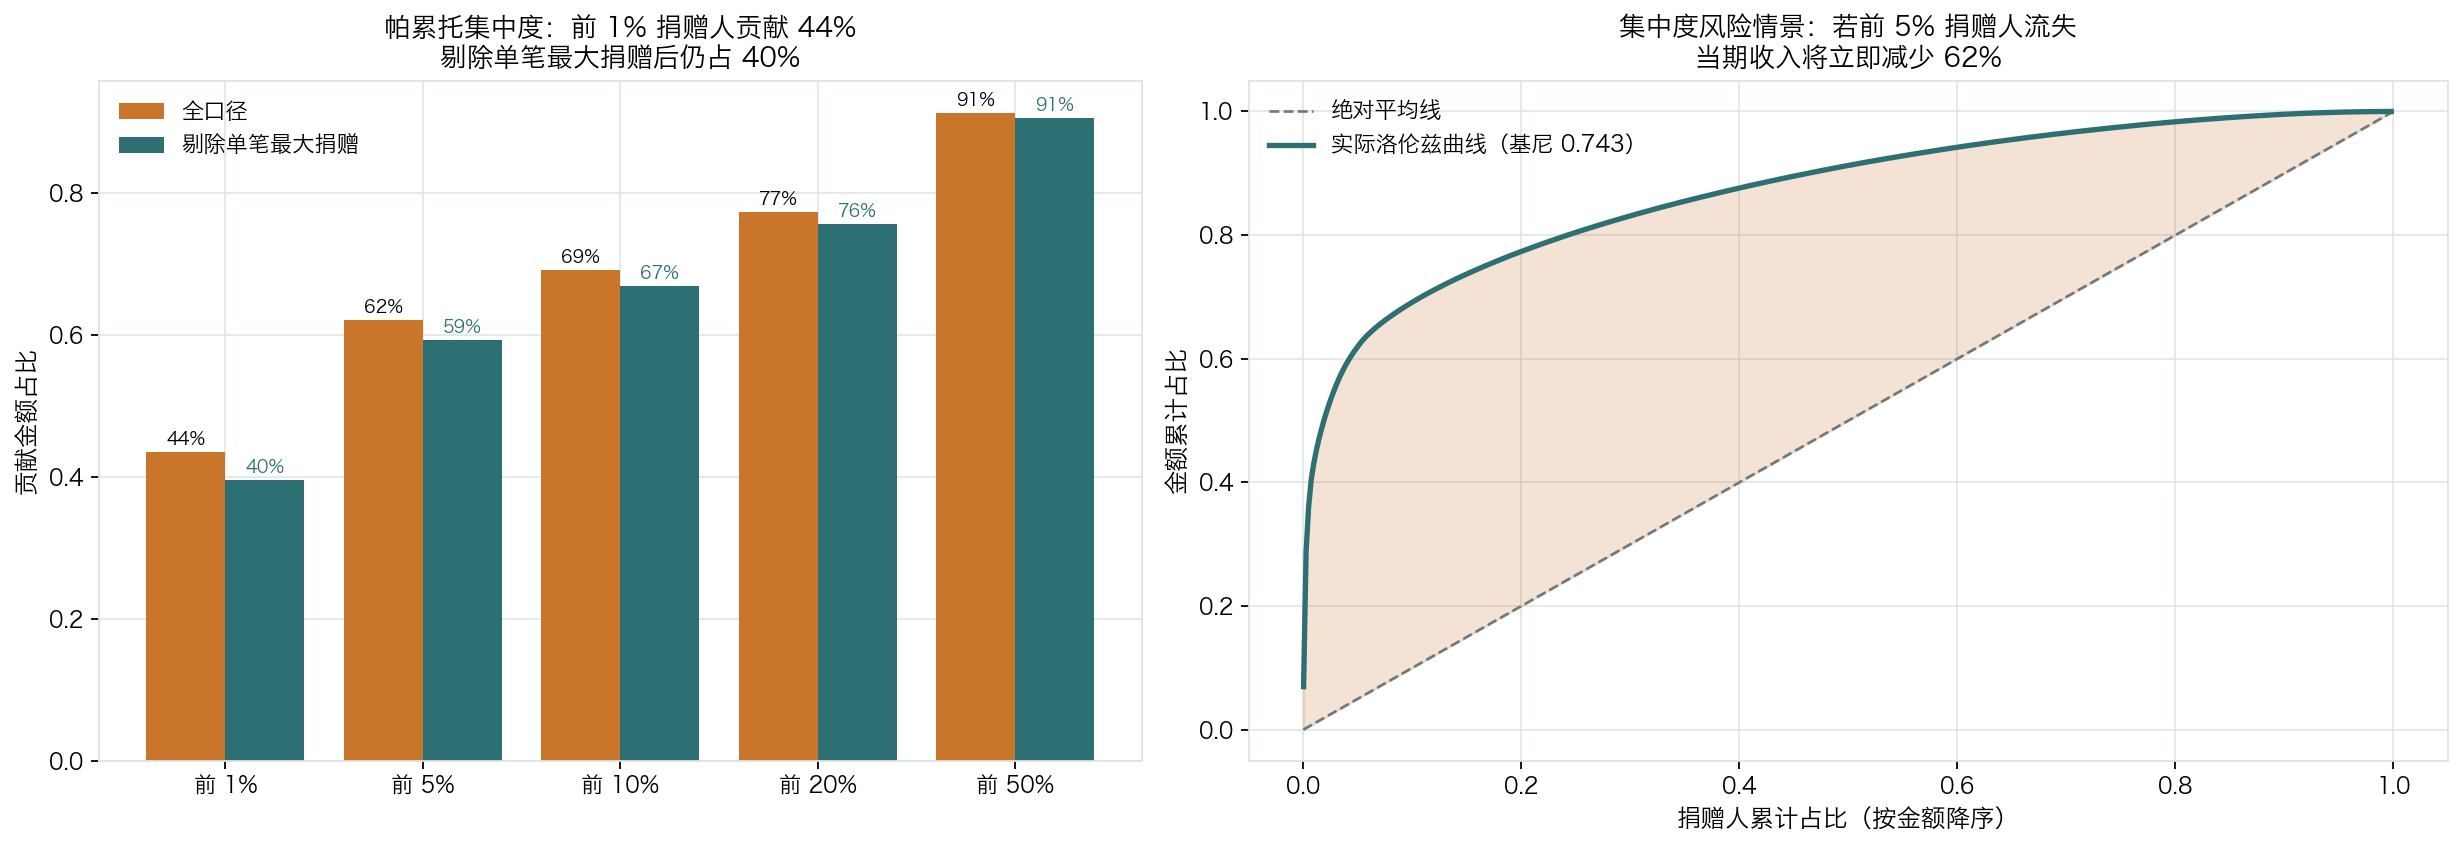

HHI 阈值判定：配置阈值 warn_above=0.25，实测 0.01027 —— 远低于阈值，说明“按捐赠人计”的集中度并不高，但“按金额计”的前 1% 贡献极高，两种口径必须同时看。
（本 notebook 自绘图表已保存：reports/figures/nb04_concentration.png）


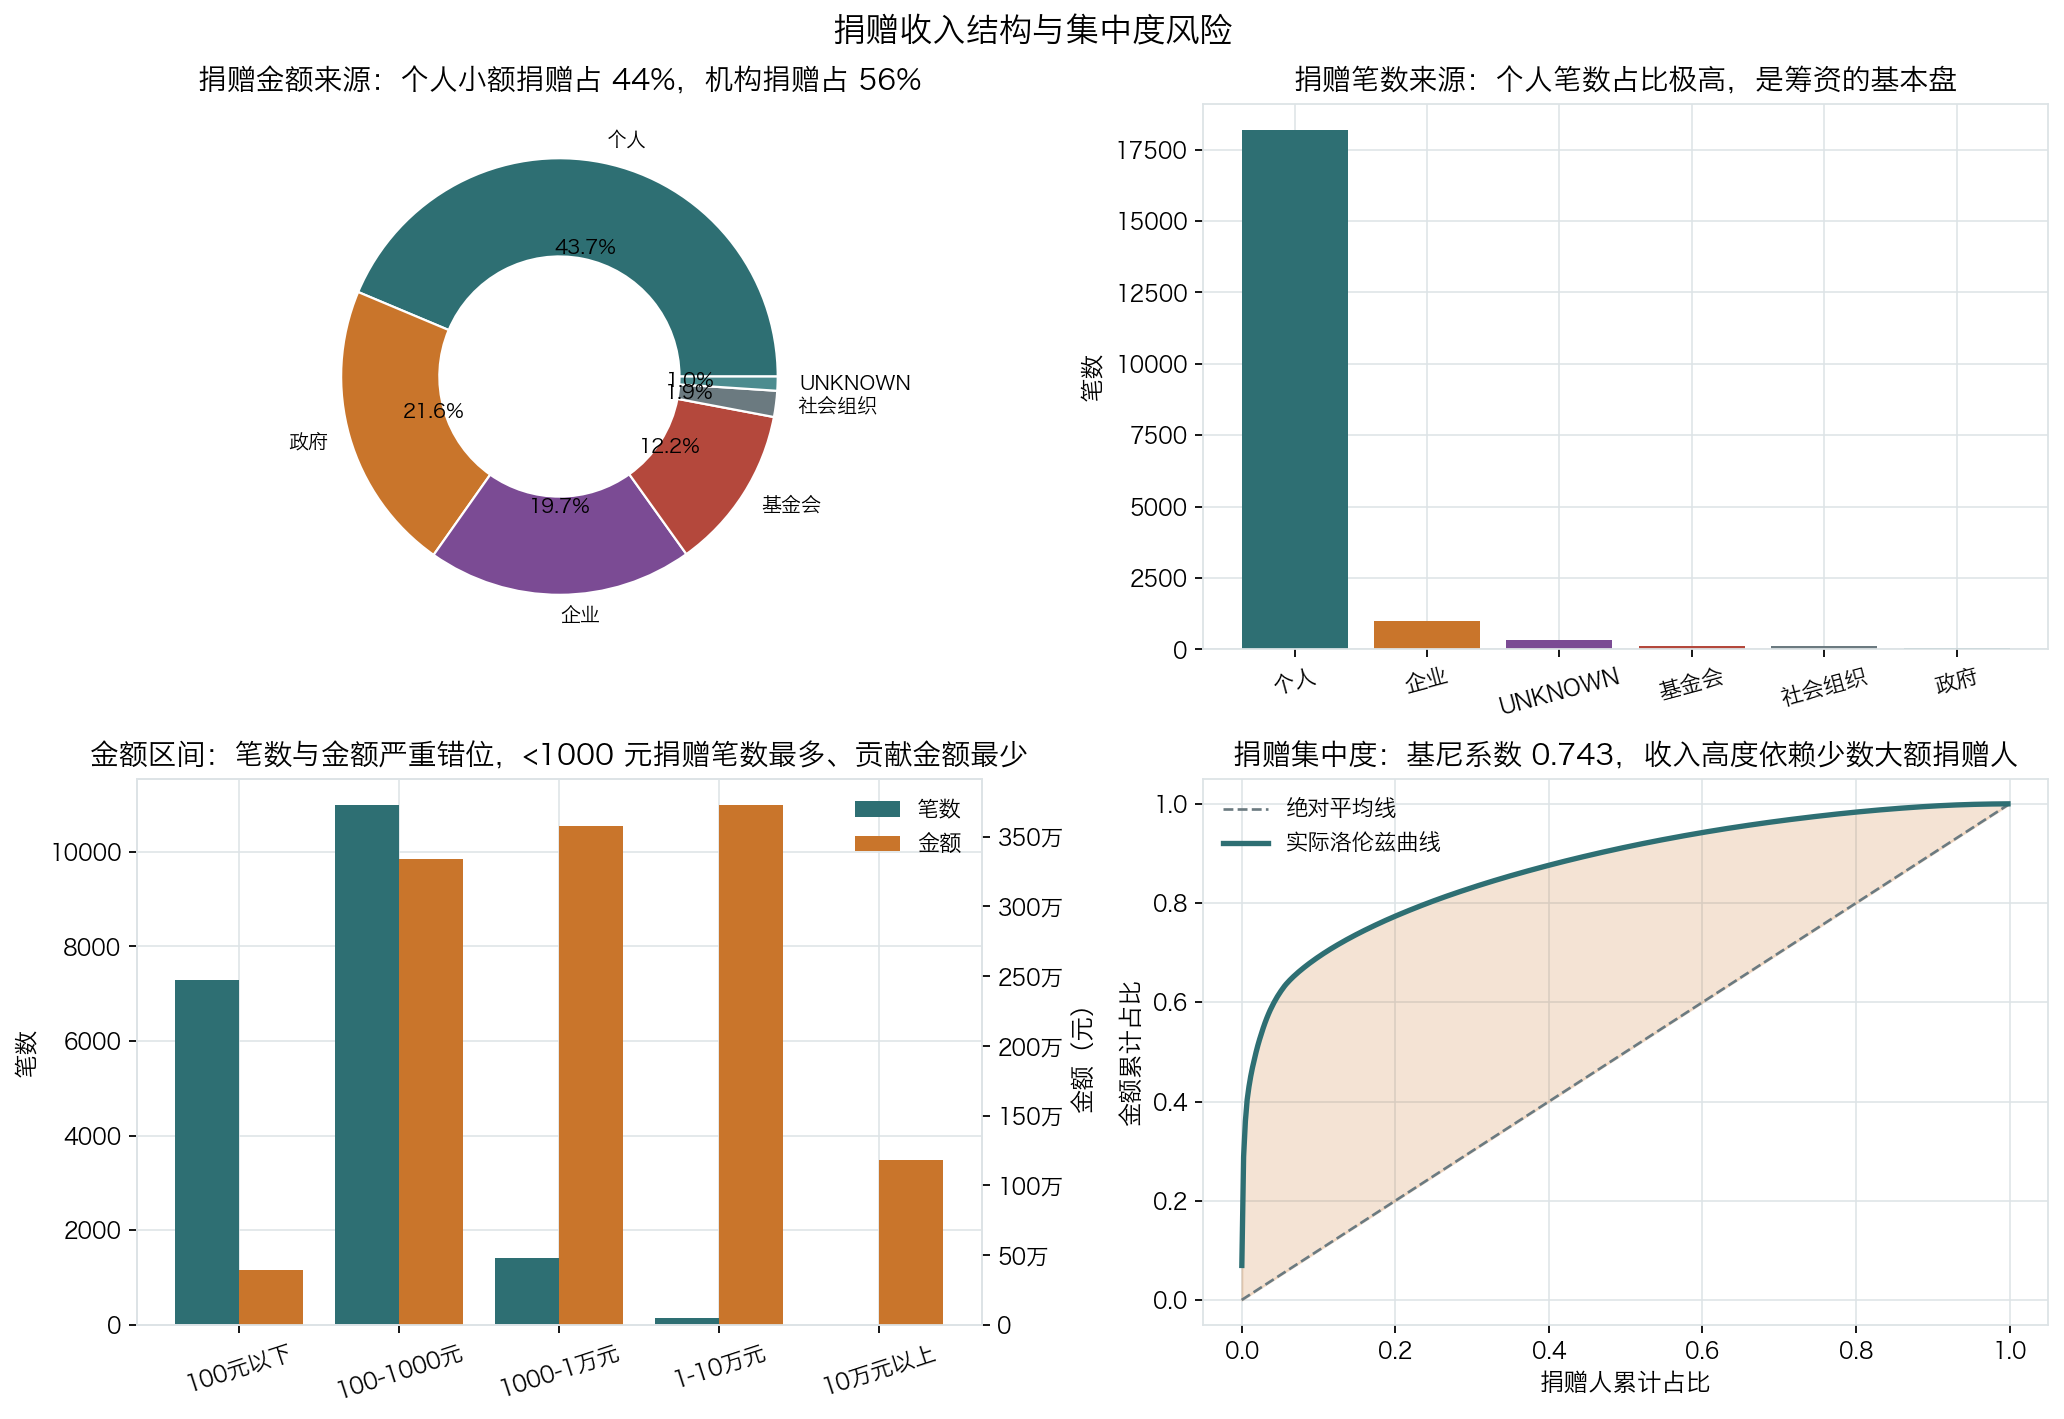

管道产出的捐赠结构与洛伦兹曲线（含金额区间与捐赠人类型结构）。


In [4]:
conc = concentration_analysis(star)
print(f"捐赠人总数 {conc['n_donors']:,}，捐赠总额 {conc['total']:,.0f} 元，"
      f"基尼系数 {conc['gini']:.4f}，HHI {conc['hhi']:.5f}，"
      f"前 10 大捐赠人金额占比 {conc['top_donors']['金额占比'].sum():.1%}")
display(conc["pareto_points"])
display(conc["top_donors"][["donor_name", "donor_type", "county", "is_recurring", "amount_cny",
                            "金额占比", "累计占比"]].head(10).round(4))

# 可比口径：剔除单笔最大捐赠后重算集中度（口径变更必须显式说明）
don = star["fact_donation"].loc[star["fact_donation"]["donor_key"] != -1].copy()
max_gift = float(don["amount_cny"].max())
don_ex = don.loc[don["amount_cny"] < max_gift]
by_donor_all = don.groupby("donor_key")["amount_cny"].sum()
by_donor_ex = don_ex.groupby("donor_key")["amount_cny"].sum()
total_ex = float(by_donor_ex.sum())


def hhi_of(series):
    return float(((series / series.sum()) ** 2).sum())


pareto_ex = []
for q in (0.01, 0.05, 0.10, 0.20, 0.50):
    k = max(1, int(np.ceil(len(by_donor_ex) * q)))
    pareto_ex.append({"口径": f"前 {q:.0%}", "金额占比（可比口径）": by_donor_ex.nlargest(k).sum() / total_ex})
pareto_ex = pd.DataFrame(pareto_ex).set_index("口径")
compare_conc = pd.DataFrame(
    {"全口径": [conc["gini"], conc["hhi"], float(conc["pareto_points"].iloc[0]["金额占比"])],
     "剔除单笔最大捐赠": [gini_coefficient(by_donor_ex.to_numpy()), hhi_of(by_donor_ex),
                          float(pareto_ex.iloc[0, 0])]},
    index=["基尼系数", "HHI", "前 1% 捐赠人金额占比"])
compare_conc["变化"] = (compare_conc["剔除单笔最大捐赠"] - compare_conc["全口径"]).round(5)
display(compare_conc.round(5))

gift = don.loc[don["amount_cny"] == max_gift].iloc[0]
loss = conc["total"] - total_ex
print(f"单笔最大捐赠 {max_gift:,.0f} 元（{gift['year_month'] if 'year_month' in gift else ''}），"
      f"占全口径捐赠总额 {max_gift / conc['total']:.1%}；剔除后基尼系数从 {conc['gini']:.4f} 变为 "
      f"{compare_conc.loc['基尼系数', '剔除单笔最大捐赠']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.4), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
pts = conc["pareto_points"]
xx = np.arange(len(pts))
ax.bar(xx - 0.2, pts["金额占比"], width=0.4, color=cfg.color("secondary"), label="全口径")
ax.bar(xx + 0.2, pareto_ex["金额占比（可比口径）"], width=0.4, color=cfg.color("primary"), label="剔除单笔最大捐赠")
ax.set_xticks(xx, pts["捐赠人占比"])
ax.set_ylabel("贡献金额占比")
ax.set_title(f"帕累托集中度：前 1% 捐赠人贡献 {pts['金额占比'].iloc[0]:.0%}\n"
             f"剔除单笔最大捐赠后仍占 {pareto_ex['金额占比（可比口径）'].iloc[0]:.0%}", fontsize=12)
ax.legend()
for i, (a, b) in enumerate(zip(pts["金额占比"], pareto_ex["金额占比（可比口径）"])):
    ax.text(i - 0.2, a + 0.01, f"{a:.0%}", ha="center", fontsize=8)
    ax.text(i + 0.2, b + 0.01, f"{b:.0%}", ha="center", fontsize=8, color=cfg.color("primary"))

ax = axes[1]
lor = conc["lorenz"]
step = max(1, len(lor) // 400)
ax.plot([0, 1], [0, 1], "--", color=cfg.color("neutral"), lw=1.2, label="绝对平均线")
ax.plot(lor["捐赠人累计占比"].to_numpy()[::step], lor["金额累计占比"].to_numpy()[::step],
        color=cfg.color("primary"), lw=2.4, label=f"实际洛伦兹曲线（基尼 {conc['gini']:.3f}）")
ax.fill_between(lor["捐赠人累计占比"].to_numpy()[::step], lor["金额累计占比"].to_numpy()[::step],
                lor["捐赠人累计占比"].to_numpy()[::step], color=cfg.color("secondary"), alpha=0.2)
ax.set_xlabel("捐赠人累计占比（按金额降序）")
ax.set_ylabel("金额累计占比")
ax.set_title(f"集中度风险情景：若前 5% 捐赠人流失\n当期收入将立即减少 "
             f"{conc['pareto_points'].set_index('捐赠人占比').loc['前 5%', '金额占比']:.0%}", fontsize=12)
ax.legend(loc="upper left")
fig.tight_layout()
show(fig, "nb04_concentration",
     f"HHI 阈值判定：配置阈值 warn_above="
     f"{cfg.threshold('donor_concentration_hhi').get('warn_above', 0.25)}，实测 {conc['hhi']:.5f} —— "
     f"远低于阈值，说明“按捐赠人计”的集中度并不高，但“按金额计”的前 1% 贡献极高，两种口径必须同时看。")

pipeline_figure("07_donation_structure.png", "管道产出的捐赠结构与洛伦兹曲线（含金额区间与捐赠人类型结构）。")

**集中度必须用两个口径同时看，否则会得出相反结论**：

- **HHI 偏低**是因为捐赠人**数量多**（分母大）——大量个人小额捐赠把指数摊平了。
  它回答的是"捐赠人结构是否分散"，答案是"很分散"。
- **前 1% 贡献极高**回答的是"金额来源是否集中"，答案同样是"高度集中"。
- 两者并不矛盾：**人数上分散、金额上集中**，是公益组织最常见、也最危险的收入结构——
  日常看似有很多支持者，但一旦头部几个大额捐赠人转向，收入会断崖式下跌。

**可比口径的必要性**：一笔应急定向捐赠会把集中度指标与年度预算基线同时抬高。
如果用它来推导"明年也应该能筹到这么多"，就是把一次性事件当成常态。
所有对外报告都应同时给出全口径与可比口径，并明确标注差异。

> 行动建议：
> 1. 建立**大额捐赠人备份计划**：对贡献前 5% 的捐赠人，逐户制定年度沟通与项目反馈计划，把关系从"人"转到"组织"（避免因个别联系人离职而流失）。
> 2. 设定**集中度红线**：例如前 1% 金额占比不超过某个比例，超出即触发筹资结构调整。
> 3. **小额渠道做留存**：个人小额捐赠的价值不在单笔金额，而在于转化为月捐与重复捐赠——用复捐率而非金额考核这部分工作。

## 4. 志愿者队列留存：招募强于留存

队列分析（cohort）按"注册年份"分组，观察各队列在每一年的活跃人数比例。
它能把"总活跃率"这种平均数掩盖的问题暴露出来：**是新招募拉动，还是老志愿者在流失？**

activity_year,队列规模,2024,2025,2026
cohort,,,,
2019,152,41,44,39
2020,276,77,81,63
2021,407,95,99,85
2022,477,118,125,107
2023,612,152,164,144
2024,633,164,191,175
2025,671,0,157,165
2026,349,0,0,76


activity_year,2024,2025,2026
cohort,,,
2019,0.2697,0.2895,0.2566
2020,0.2790,0.2935,0.2283
2021,0.2334,0.2432,0.2088
2022,0.2474,0.2621,0.2243
2023,0.2484,0.2680,0.2353
2024,0.2591,0.3017,0.2765
2025,0.0000,0.2340,0.2459
2026,0.0000,0.0000,0.2178


注册满一年及以上队列的首次活跃年留存率中位数 24.8%，最近观察年留存率中位数 23.2%


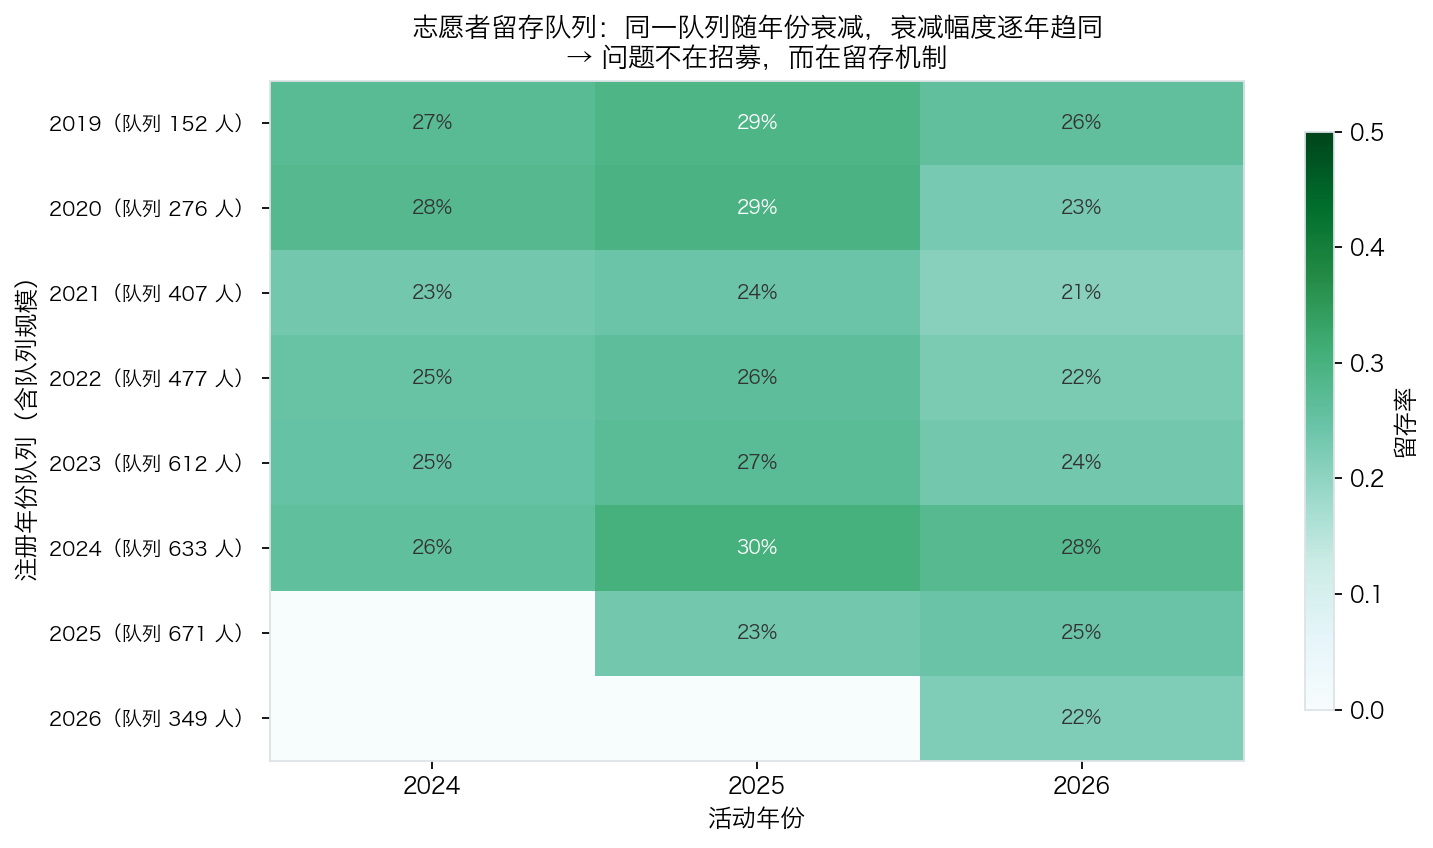

队列规模最大的是 671 人（2025 年注册）；各队列到最近观察年的留存率中位数为 23.2%。
（本 notebook 自绘图表已保存：reports/figures/nb04_cohort.png）


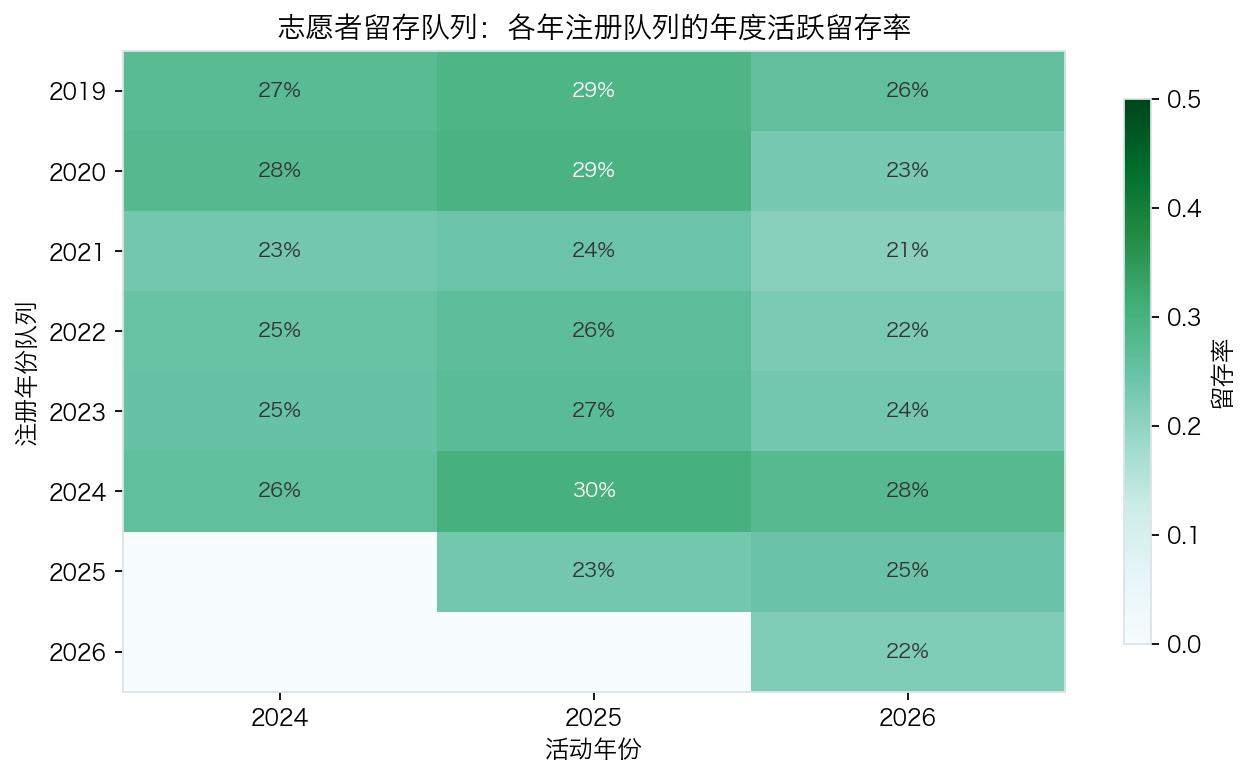

管道产出的留存队列热力图。


,指标名称,指标值,单位,口径公式
14,志愿者一年留存率,0.239364,比例,注册满 12 个月且近 6 个月仍有服务的人数 / 注册满 12 个月人数


In [5]:
cohort = cohort_retention(star)
# 公共 API 未导出 retention_rates，此处按队列规模换算留存率，口径与 analyze.retention_rates 一致（分母=队列规模）
rates = cohort.drop(columns=["队列规模"]).div(cohort["队列规模"].replace(0, np.nan), axis=0).round(4)
display(cohort)
display(rates)

first_year_rate = rates.apply(lambda r: r.dropna().iloc[0] if r.dropna().size else np.nan, axis=1)
latest_year_rate = rates.apply(lambda r: r.dropna().iloc[-1] if r.dropna().size else np.nan, axis=1)
print(f"注册满一年及以上队列的首次活跃年留存率中位数 {first_year_rate.median():.1%}，"
      f"最近观察年留存率中位数 {latest_year_rate.median():.1%}")

fig, ax = plt.subplots(figsize=(9.5, 5.4))
im = ax.imshow(rates.to_numpy(), aspect="auto", cmap="BuGn", vmin=0,
               vmax=max(0.5, np.nanmax(rates.to_numpy())))
ax.set_xticks(range(rates.shape[1]), [str(c) for c in rates.columns])
ax.set_yticks(range(rates.shape[0]), [f"{i}（队列 {int(n)} 人）" for i, n in zip(rates.index, cohort["队列规模"])],
              fontsize=9)
for i in range(rates.shape[0]):
    for j in range(rates.shape[1]):
        v = rates.iloc[i, j]
        if pd.notna(v) and v > 0:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8.5,
                    color="white" if v > 0.28 else "#333333")
ax.set_xlabel("活动年份")
ax.set_ylabel("注册年份队列（含队列规模）")
ax.set_title("志愿者留存队列：同一队列随年份衰减，衰减幅度逐年趋同\n→ 问题不在招募，而在留存机制", fontsize=12)
ax.grid(False)
fig.colorbar(im, ax=ax, label="留存率", shrink=0.85)
fig.tight_layout()
show(fig, "nb04_cohort",
     f"队列规模最大的是 {int(cohort['队列规模'].max())} 人（{cohort['队列规模'].idxmax()} 年注册）；"
     f"各队列到最近观察年的留存率中位数为 {latest_year_rate.median():.1%}。")

pipeline_figure("11_cohort_retention.png", "管道产出的留存队列热力图。")

kpi_retention = arts["kpis"].loc[arts["kpis"]["指标名称"].str.contains("留存", na=False)]
if len(kpi_retention):
    display(kpi_retention[["指标名称", "指标值", "单位", "口径公式"]])

**留存怎么看**：

- **横向看（同一队列跨年）**：留存率逐年衰减是正常的，但**衰减速度**是关键。
  如果第一年就掉到一半以下，说明新志愿者的首次体验或匹配度有问题。
- **纵向看（不同队列同年）**：较新的队列在相同"队列年龄"上的留存率如果高于老队列，
  说明招募与入职流程在改善；反之则说明组织支持能力在下降。
- **分母必须一起看**：小队列的比例波动极大（很多人数的 1 人变化就是好几个百分点），
  所以热力图左侧标注了队列规模。**任何留存率结论都要带队列规模。**

> 行动建议：
> 1. 对新注册志愿者建立**前 90 天陪伴机制**（首次服务前的培训、首次服务后的回访、第二次服务邀约），
>    这是留存率弹性最大的干预点。
> 2. 对"注册满一年、近半年无服务"的人员做定向激活（本项目 KPI 中有同名口径指标），
>    名单可直接从事实表导出。
> 3. 把留存率纳入志愿者管理的季度指标，与招募人数并列考核——只考核招募会持续稀释质量。

## 5. 指标间关系：相关性与弹性

最后一组分析回答"指标之间是否联动"。这里用 **Spearman 秩相关**（对离群点稳健，适合右偏数据），
以及**双对数回归**估计"捐赠额 → 服务时长"的弹性。

**关键纪律：统计不显著时不能按点估计讲故事。** 弹性点估计再大，只要 p 值不达标，
就不能对外宣称"捐赠下滑会压缩服务供给"。

,service_hours,active_volunteers,service_count,service_visits,donation_amount,donation_count,donor_count,satisfaction_mean,actual_cny,execution_rate
service_hours,1.000,0.957,0.991,0.754,0.327,0.778,0.777,-0.308,0.805,-0.028
active_volunteers,0.957,1.000,0.933,0.826,0.208,0.668,0.671,-0.273,0.889,0.001
service_count,0.991,0.933,1.000,0.730,0.340,0.789,0.788,-0.298,0.778,-0.018
service_visits,0.754,0.826,0.730,1.000,0.156,0.459,0.431,-0.271,0.857,0.073
donation_amount,0.327,0.208,0.340,0.156,1.000,0.444,0.471,-0.224,0.131,0.107
donation_count,0.778,0.668,0.789,0.459,0.444,1.000,0.990,-0.288,0.557,-0.122
donor_count,0.777,0.671,0.788,0.431,0.471,0.990,1.000,-0.298,0.538,-0.079
satisfaction_mean,-0.308,-0.273,-0.298,-0.271,-0.224,-0.288,-0.298,1.000,-0.241,-0.334
actual_cny,0.805,0.889,0.778,0.857,0.131,0.557,0.538,-0.241,1.000,0.079
execution_rate,-0.028,0.001,-0.018,0.073,0.107,-0.122,-0.079,-0.334,0.079,1.000


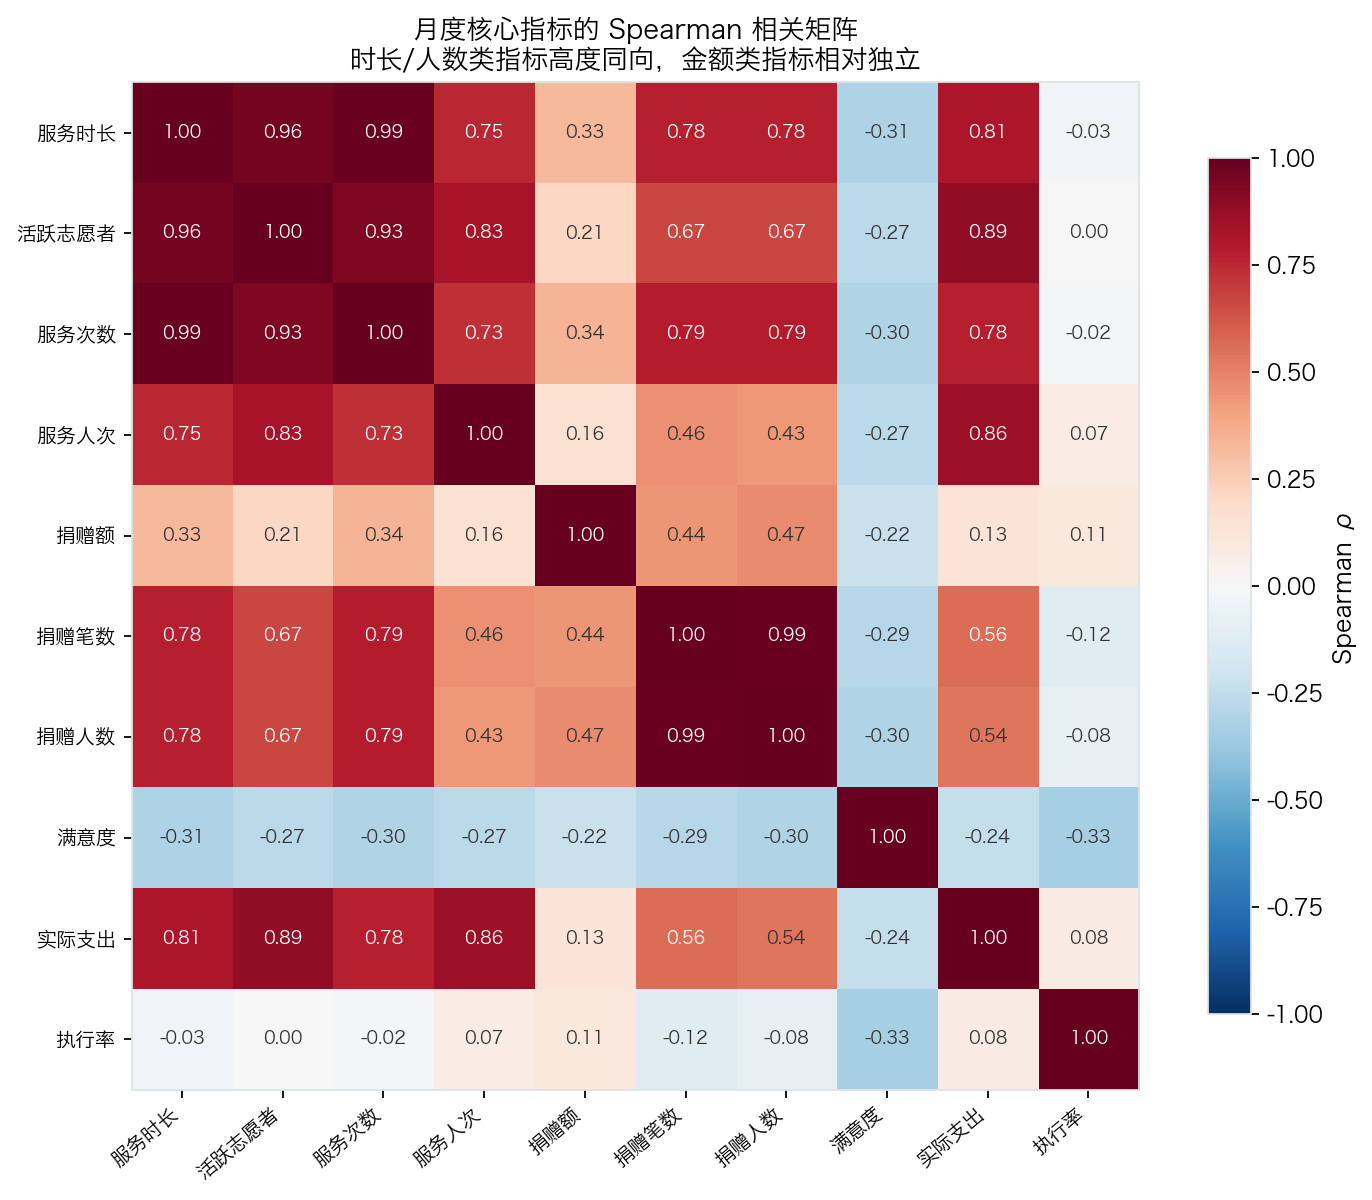

读法：|ρ| 越大越同向。服务时长与活跃志愿者高度相关（人力驱动），而捐赠额与它们的相关性明显更弱——说明资金与人力是两条相对独立的供给曲线。
（本 notebook 自绘图表已保存：reports/figures/nb04_correlation.png）
        elasticity：0.5245
         intercept：0.5685
                r2：0.0528
           p_value：0.23027836533165794
                 n：29
 elasticity_2026H1：-0.0266
       significant：False
           verdict：不显著
        conclusion：未发现统计显著的联动关系（弹性点估计 0.52，但 p=0.230 ≥ 0.05，R²=0.05）：月度服务时长的变化主要由志愿者供给与项目排期驱动，资金波动尚未在月度尺度上传导到服务量


In [6]:
corr = correlation_analysis(panel)
display(corr)

fig, ax = plt.subplots(figsize=(9.6, 7.6))
im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
labels = ["服务时长", "活跃志愿者", "服务次数", "服务人次", "捐赠额", "捐赠笔数",
          "捐赠人数", "满意度", "实际支出", "执行率"][: corr.shape[0]]
ax.set_xticks(range(corr.shape[0]), labels, rotation=40, ha="right", fontsize=9)
ax.set_yticks(range(corr.shape[0]), labels, fontsize=9)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.55 else "#333333")
ax.set_title("月度核心指标的 Spearman 相关矩阵\n时长/人数类指标高度同向，金额类指标相对独立", fontsize=12)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Spearman ρ", shrink=0.85)
fig.tight_layout()
show(fig, "nb04_correlation",
     "读法：|ρ| 越大越同向。服务时长与活跃志愿者高度相关（人力驱动），"
     "而捐赠额与它们的相关性明显更弱——说明资金与人力是两条相对独立的供给曲线。")

elasticity = donation_service_elasticity(panel)
for k in ["elasticity", "intercept", "r2", "p_value", "n", "elasticity_2026H1", "significant",
          "verdict", "conclusion"]:
    print(f"{k:>18}：{elasticity.get(k)}")

**相关性与弹性的业务含义**：

- **服务时长 ↔ 活跃志愿者**高度同向：服务产能由**人力**驱动。这意味着排班与志愿者动员是产能的第一约束，
  资金只能通过"够不够支撑志愿者出勤"（交通、物资、补贴）间接影响产能。
- **捐赠额与服务时长相关性弱**：资金与人力是两条独立的供给曲线，组织的抗风险能力正来自这一点——
  资金收紧时人力未必同步收缩。本 notebook 用双对数回归检验了这一点，结论以代码输出的显著性判定为准。
- **执行率与满意度呈负相关**（具体数值见上方相关矩阵）："把钱按计划花完"与"服务体验好"并不一致。
  一个合理解释是——预算执行偏快的项目往往在赶进度，服务过程被压缩，体验随之下降。
  这正是评分卡把"执行"与"质量"分列两个维度、而不是合并成一个"绩效分"的原因。
- **满意度与投入规模的关联很弱**：满意度更多取决于服务设计与执行细节，而不是堆时长、堆金额。
  这也解释了为什么"延长服务时间"不是提升满意度的有效手段。

> 汇报纪律：任何"X 影响 Y"的表述都必须带上显著性检验结果。
> 弹性点估计 0.52 却不显著时，正确的表述是"未发现统计显著的联动关系"，
> 而不是"弹性为 0.52，说明有较强联动"。

## 6. 行动建议

下面把前五个 notebook 的所有量化结论收敛成一份可执行的行动清单。
每条建议都附上**触发条件与量化依据**，全部数字由上方代码实时计算，可直接引用。

In [7]:
# ---- 从各分析结果中提取行动依据（全部动态计算，不写死任何数字） -----------------
d_projects = scorecard[scorecard["评级"] == "D 待改进"]
c_projects = scorecard[scorecard["评级"] == "C 合格"]
low_exec = scorecard[scorecard["execution_rate"] < cfg.threshold("project_execution_rate").get("warn_below", 0.85)]
low_exec = low_exec.dropna(subset=["execution_rate"])
high_cost_low_sat = scorecard[(scorecard["cost_per_visit"] > scorecard["cost_per_visit"].median())
                              & (scorecard["satisfaction_mean"] < scorecard["satisfaction_mean"].median())]

equity = (star["fact_beneficiary_service"]
          .merge(star["dim_beneficiary"][["beneficiary_key", "household_type"]], on="beneficiary_key", how="left")
          .assign(sat=lambda d: pd.to_numeric(d["satisfaction_score"], errors="coerce"))
          .dropna(subset=["sat"]))
equity_group = equity.groupby("household_type")["sat"].agg(["size", "mean"])
equity_group = equity_group[equity_group["size"] >= 30].sort_values("mean")
worst_household = equity_group.index[0]
equity_gap = float(equity_group["mean"].max() - equity_group["mean"].min())

fivetime = conc["pareto_points"].set_index("捐赠人占比")
top5_rate = float(fivetime.loc["前 5%", "金额占比"])
top5_amount = float(fivetime.loc["前 5%", "金额"])
recurring_share = float(conc["top_donors"]["is_recurring"].sum()) / len(conc["top_donors"])

season_tbl = monthly_seasonality(panel)
peak_row = season_tbl.loc[season_tbl["相对强度指数"].idxmax()]
trough_row = season_tbl.loc[season_tbl["相对强度指数"].idxmin()]
hhi_warn = cfg.threshold("donor_concentration_hhi").get("warn_above", 0.25)

unknown_share = 1 - float(scorecard["category"].notna().mean())
sat_missing = float(star["fact_beneficiary_service"]["satisfaction_score"].isna().mean())

actions = []
named_d = d_projects["project_name"].dropna().astype(str)
unnamed_d = int(d_projects["project_name"].isna().sum())
name_hint = "、".join(named_d.head(3)) + (" 等" if len(named_d) > 3 else "")
if unnamed_d:
    name_hint += f"；另有 {unnamed_d} 个源头档案缺少项目名称，需先补录再复盘"
actions.append(
    f"① 项目复盘（本月启动）：对 {len(d_projects)} 个「D 待改进」项目逐一复盘"
    f"（{name_hint}，综合评分 {d_projects['综合评分'].min():.3f}–"
    f"{d_projects['综合评分'].max():.3f}）；对 {len(c_projects)} 个「C 合格」项目做抽查。"
    f"复盘重点看两项：单位服务成本是否高于全体中位数 "
    f"{scorecard['cost_per_visit'].median():,.0f} 元/人次、目标覆盖率是否低于 "
    f"{scorecard['target_coverage'].median():.0%}。")
actions.append(
    f"② 预算执行排查：{len(low_exec)} 个项目的预算执行率低于预警线 "
    f"{cfg.threshold('project_execution_rate').get('warn_below', 0.85):.0%}"
    f"（最低 {low_exec['execution_rate'].min():.2f}）。这类偏离多为跨月入账或进度滞后，"
    f"应与财务联合核对报销单据归属期，而不是直接判定项目执行不力。")
actions.append(
    f"③ 服务公平性专项：满意度最低的家庭类型是「{worst_household}」"
    f"（{equity_group['mean'].iloc[0]:.3f} 分，n={int(equity_group['size'].iloc[0]):,}），"
    f"与最高组相差 {equity_gap:.3f} 分。对其建立个案复盘机制（服务频次、双语匹配、跟进闭环），"
    f"并把该组满意度单列为质量层指标。")
actions.append(
    f"④ 资金风险对冲：前 5% 捐赠人贡献 {top5_rate:.1%}（{top5_amount:,.0f} 元），"
    f"而 HHI 仅 {conc['hhi']:.5f}（阈值 {hhi_warn}）——人数分散但金额集中。"
    f"建议对前 5% 捐赠人逐户制定年度沟通与项目反馈计划，把关系从个人转移到组织；"
    f"并设定“前 1% 金额占比不超过 {fivetime.loc['前 1%', '金额占比']:.0%}”的内部预警线。")
actions.append(
    f"⑤ 大额捐赠的披露口径：单笔最大捐赠 {max_gift:,.0f} 元，占全口径捐赠总额 "
    f"{max_gift / conc['total']:.1%}。所有对外材料同时给出全口径与剔除该笔后的可比口径"
    f"（基尼系数 {conc['gini']:.3f} → {compare_conc.loc['基尼系数', '剔除单笔最大捐赠']:.3f}），"
    f"避免把一次性应急捐赠当成常态收入写进下一年度目标。")
actions.append(
    f"⑥ 志愿者留存激活：注册满一年以上队列的最近观察年留存率中位数 "
    f"{latest_year_rate.median():.1%}。建议对新注册志愿者建立“前 90 天陪伴机制”，"
    f"并对注册满一年、近半年无服务记录的人员做定向激活（名单可由 fact_volunteer_service 直接导出）。")
actions.append(
    f"⑦ 季节化排班与预算：服务强度最高月份为 {peak_row['月度名称']}"
    f"（指数 {peak_row['相对强度指数']:.2f}），最低为 {trough_row['月度名称']}"
    f"（指数 {trough_row['相对强度指数']:.2f}），极差 "
    f"{peak_row['相对强度指数'] / trough_row['相对强度指数']:.1f} 倍。"
    f"排班提前一个月启动；年度预算按该指数分配月度额度，淡季安排培训、档案整理与筹资拜访。")
actions.append(
    f"⑧ 数据治理与口径纪律：项目档案类别缺失占比 {unknown_share:.1%}，"
    f"服务满意度评分缺失占比 {sat_missing:.1%}。建议设定数据 SLO——"
    f"月度剔除率/修正率不超过历史中位数的 2 倍即触发复盘；报表中固定披露分组样本量与 UNKNOWN 占比，"
    f"并对所有趋势结论标注“是否剥离季节”“是否含一次性大额捐赠”。")

print("=" * 92)
print("行动建议清单（量化依据来自本 notebook 上方代码的实时计算结果）")
print("=" * 92)
for line in actions:
    print(line)
    print("-" * 92)
print(f"配套考核建议：项目层用「综合评分 + 单位成本」，筹资层用「前 5% 金额占比 + 复捐率」，"
      f"志愿者层用「留存率」而非「招募人数」（前 10 大捐赠人中经常性捐赠人占比 {recurring_share:.0%}，"
      f"说明经常性捐赠仍有提升空间）。")

行动建议清单（量化依据来自本 notebook 上方代码的实时计算结果）
① 项目复盘（本月启动）：对 9 个「D 待改进」项目逐一复盘（维西-松茸采摘技能培训、维西-农村饮水安全改善(3期)、维西-高原湖泊水质监测 等；另有 1 个源头档案缺少项目名称，需先补录再复盘，综合评分 0.091–0.341）；对 20 个「C 合格」项目做抽查。复盘重点看两项：单位服务成本是否高于全体中位数 936 元/人次、目标覆盖率是否低于 79%。
--------------------------------------------------------------------------------------------
② 预算执行排查：7 个项目的预算执行率低于预警线 85%（最低 0.72）。这类偏离多为跨月入账或进度滞后，应与财务联合核对报销单据归属期，而不是直接判定项目执行不力。
--------------------------------------------------------------------------------------------
③ 服务公平性专项：满意度最低的家庭类型是「事实无人抚养儿童」（3.995 分，n=779），与最高组相差 0.435 分。对其建立个案复盘机制（服务频次、双语匹配、跟进闭环），并把该组满意度单列为质量层指标。
--------------------------------------------------------------------------------------------
④ 资金风险对冲：前 5% 捐赠人贡献 62.0%（7,577,475 元），而 HHI 仅 0.01027（阈值 0.25）——人数分散但金额集中。建议对前 5% 捐赠人逐户制定年度沟通与项目反馈计划，把关系从个人转移到组织；并设定“前 1% 金额占比不超过 44%”的内部预警线。
--------------------------------------------------------------------------------------------
⑤ 大额捐赠的披露口径：单笔最大捐赠 850,000 元，占全口径捐赠总额 7.0%。所有对外材料同时给出全口径与剔除该笔后的可比口径（基尼系数 